Brayden Yow  
09/27/2026  
lab 5 — Orbital Mechanics Simulator

In [1]:
import numpy as np 
import matplotlib.pyplot as plt

Part A — A Single Orbit with Velocity Verlet 

In [2]:
def verlet_step(r, v, a, dt, accel_func):
    """One Velocity Verlet step. accel_func(r) returns acceleration at position r."""
    r_new = r + v * dt + 0.5 * a * dt**2
    a_new = accel_func(r_new)
    v_new = v + 0.5 * (a + a_new) * dt
    return r_new, v_new, a_new

In [3]:
G, M = 1.0, 1.0       # star at origin

def accel(r):
    dist = np.linalg.norm(r)
    return -G * M * r / dist**3

# Initial conditions for a bound elliptical orbit
r = np.array([1.0, 0.0])
v = np.array([0.0, 0.8])   # less than circular speed (=1.0) -> ellipse
a = accel(r)

dt = 0.001
rs_orbit = [r.copy()]
vs_orbit = [v.copy()]
times = [0.0]

for i in range(20000):
    r, v, a = verlet_step(r, v, a, dt, accel)
    rs_orbit.append(r.copy())
    vs_orbit.append(v.copy())
    times.append(i * dt)
rs_orbit = np.array(rs_orbit)
vs_orbit = np.array(vs_orbit)
times = np.array(times)


Plotting the orbit of a body about a star with given varibles.

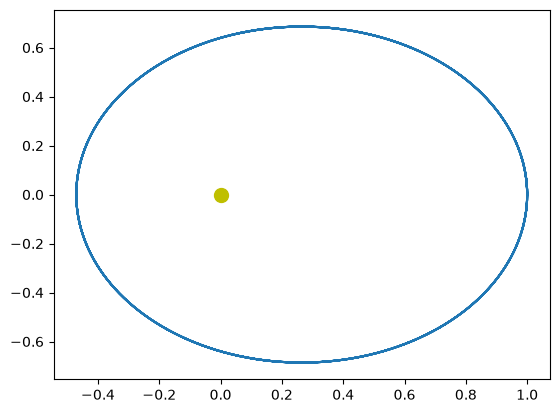

In [4]:
plt.plot(0, 0, "yo", markersize=10, label="Star")

plt.plot(rs_orbit[:,0], rs_orbit[:,1], label="Ellipse v0 = 0.8")

To make sure it's closed a plot of total energy and angular momentum vs. time should be flat

In [5]:
def energy(r, v, G=1.0, M=1.0, m=1.0):
    ke = 0.5 * m * np.dot(v, v)
    pe = -G * M * m / np.linalg.norm(r)
    return ke + pe

def ang_momentum(r, v, m=1.0):
    # 2D cross product r x v is a scalar
    return m * (r[0] * v[1] - r[1] * v[0])

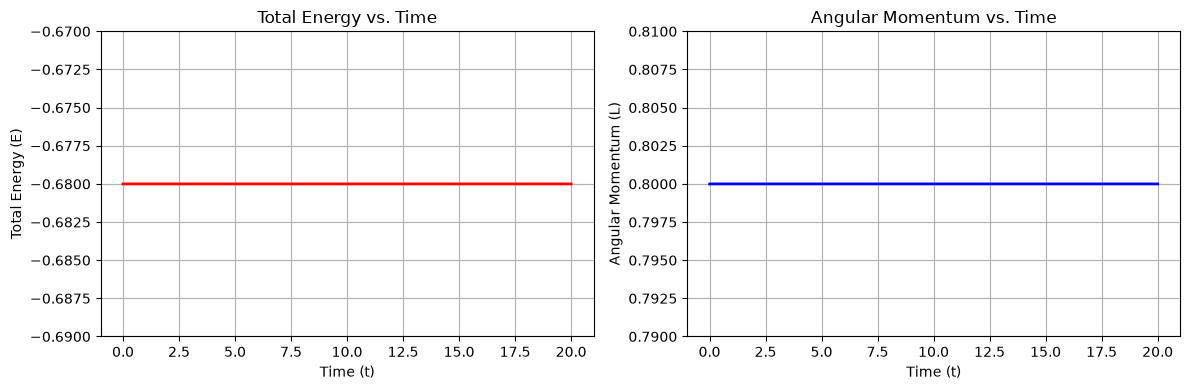

In [6]:
# Calculate energy and angular momentum for every time step
energies = [energy(rs_orbit[i], vs_orbit[i]) for i in range(len(times))]
momenta = [ang_momentum(rs_orbit[i], vs_orbit[i]) for i in range(len(times))]

# Create a side-by-side plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot Energy vs Time
ax1.plot(times, energies, color="red", linewidth=2)
ax1.set_xlabel("Time (t)")
ax1.set_ylabel("Total Energy (E)")
ax1.set_title("Total Energy vs. Time")
ax1.grid(True)
ax1.set_ylim(energies[0] - 0.01, energies[0] + 0.01) # Zoom in to confirm stability

# Plot Angular Momentum vs Time
ax2.plot(times, momenta, color="blue", linewidth=2)
ax2.set_xlabel("Time (t)")
ax2.set_ylabel("Angular Momentum (L)")
ax2.set_title("Angular Momentum vs. Time")
ax2.grid(True)
ax2.set_ylim(momenta[0] - 0.01, momenta[0] + 0.01)

plt.tight_layout()
plt.show()


**Interpret**: Is your starting point periapsis or apoapsis?  How do you know from v0 = 0.8 compared to the circular speed of 1.0?

With the speed of 0.8 there is not enough energy to go further from the star this means we must be at apoapsis. The instant after the starting condition the distance will shrink as the orbit continues. 


**Part B — The Integrator Showdown**

In [7]:
def simulate(method, dt, n_steps):
    """
    Simulates a bound orbit using the specified integration method.
    Returns: rs (positions array), vs (velocities array), ts (times array)
    """
    # Global constants and initial conditions from Part A
    G, M = 1.0, 1.0
    r = np.array([1.0, 0.0])
    v = np.array([0.0, 0.8])
    a = accel(r)
    
    # Storage arrays
    rs = [r.copy()]
    vs = [v.copy()]
    ts = [0.0]
    
    for step in range(n_steps):
        if method == 'euler':
            # 1. Update position using current velocity
            r_new = r + v * dt
            # 2. Compute acceleration at current position
            a = accel(r)
            # 3. Update velocity using current acceleration
            v_new = v + a * dt
            
        elif method == 'euler-cromer':
            # 1. Compute acceleration at current position
            a = accel(r)
            # 2. Update velocity first
            v_new = v + a * dt
            # 3. Update position using the *new* velocity
            r_new = r + v_new * dt
            
        elif method == 'verlet':
            # Use your verlet_step function from Part A
            r_new, v_new, a_new = verlet_step(r, v, a, dt, accel)
            a = a_new 
            
        else:
            raise ValueError(f"Unknown method: {method}")
            
        # Update trackers
        r, v = r_new, v_new
        rs.append(r.copy())
        vs.append(v.copy())
        ts.append((step + 1) * dt)
        
    return np.array(rs), np.array(vs), np.array(ts)


Running with the same nuber of steps and value of dt.

In [8]:
dt = 0.001
n_steps = 20000

rs_euler, vs_euler, ts_euler = simulate('euler', dt, n_steps)
rs_cromer, vs_cromer, ts_cromer = simulate('euler-cromer', dt, n_steps)
rs_verlet, vs_verlet, ts_verlet = simulate('verlet', dt, n_steps)


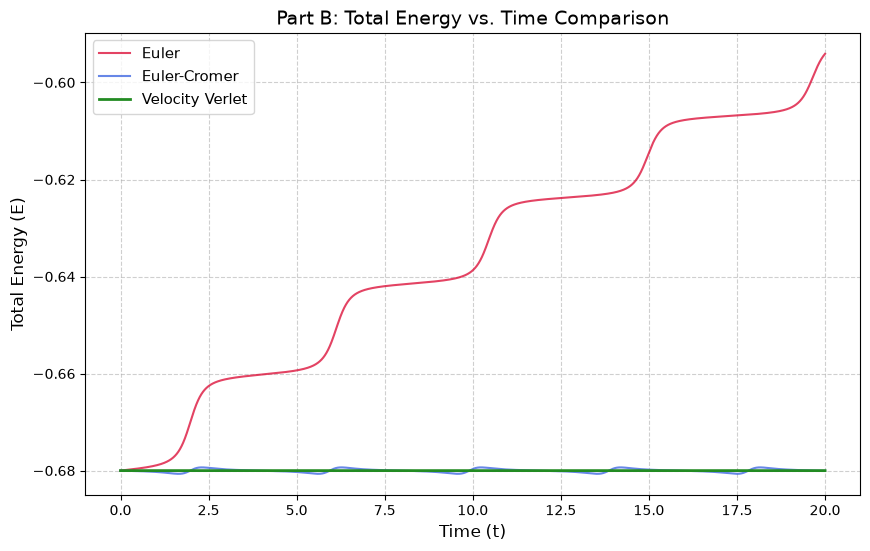

In [9]:
# 1. Calculate energy for each method at every time step
energies_euler = [energy(r, v) for r, v in zip(rs_euler, vs_euler)]
energies_cromer = [energy(r, v) for r, v in zip(rs_cromer, vs_cromer)]
energies_verlet = [energy(r, v) for r, v in zip(rs_verlet, vs_verlet)]

# 2. Plot total energy vs. time on a single axis
plt.figure(figsize=(10, 6))

plt.plot(ts_euler, energies_euler, label="Euler", color="crimson", alpha=0.8)
plt.plot(ts_cromer, energies_cromer, label="Euler-Cromer", color="royalblue", alpha=0.8)
plt.plot(ts_verlet, energies_verlet, label="Velocity Verlet", color="forestgreen", linewidth=2)

# 3. Formatting options
plt.xlabel("Time (t)", fontsize=12)
plt.ylabel("Total Energy (E)", fontsize=12)
plt.title("Part B: Total Energy vs. Time Comparison", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)

plt.show()


In [10]:
def max_fractional_error(energies):
    energies = np.array(energies)
    E0 = energies[0]
    # Compute relative differences from the starting energy
    fractional_errors = np.abs((energies - E0) / E0)
    # Return the maximum error encountered during the simulation
    return np.max(fractional_errors)

# Calculate for each method
err_euler = max_fractional_error(energies_euler)
err_cromer = max_fractional_error(energies_cromer)
err_verlet = max_fractional_error(energies_verlet)

# Print a formatted summary table
print(f"{'Method':<15} | {'Max Fractional Energy Error |Delta E / E0|':<30}")
print("-" * 55)
print(f"{'Euler':<15} | {err_euler:.6e}")
print(f"{'Euler-Cromer':<15} | {err_cromer:.6e}")
print(f"{'Verlet':<15} | {err_verlet:.6e}")


Method          | Max Fractional Energy Error |Delta E / E0|
-------------------------------------------------------
Euler           | 1.263350e-01
Euler-Cromer    | 9.763462e-04
Verlet          | 2.131864e-06


| Method | Maximum fractional energy error | 
|---|---:|
| Euler | 1.263350e-01 |
| Euler-Cromer | 9.763462e-04 |
| Velocity Verlet | 2.131864e-06 |

**Write the analysis: Why does Euler gain energy and spiral outward?  Why is Verlet stable even though it's only second-order accurate?  Connect this to the word "symplectic."**
As discussed in previous labs the order of operations in the Euler method is the cause of the additional energy. This is to say it uses the current acceleration to predict the position on the next cycle. This causes a slight overshoot in the total energy that compounds. 
The Verlet is so much more accurate due to its usage the average of the acceleration at the moment and the next acceleration step to find position and velocity. This prevents the compounding errors that are found in Euler. 
The word symplectic refers to an integrator whose purpose is to preserve geometry of phase spaces. This is a way to ensure that a system maintains global conservation of energy and angular momentum.


**Part C — Verify Kepler's Three Laws**

Using the Velocity Verlet trajectory from Part A, we can show the bound orbit is a closed ellipse. We estimate the semi-major axis $a$ by calculating the average of the minimum and maximum distances from the central star.

In [11]:
# Calculate the distance from the origin for every position step in the orbit
distances = np.linalg.norm(rs_orbit, axis=1)

# Find the minimum (periapsis) and maximum (apoapsis) distances
r_min = np.min(distances)
r_max = np.max(distances)

# Calculate the estimated semi-major axis
a_estimated = (r_min + r_max) / 2.0

print(f"Minimum distance (r_min): {r_min:.5f}")
print(f"Maximum distance (r_max): {r_max:.5f}")
print(f"Estimated semi-major axis (a): {a_estimated:.5f}")


Minimum distance (r_min): 0.47059
Maximum distance (r_max): 1.00000
Estimated semi-major axis (a): 0.73529



We compute the area swept per time step, $\frac{1}{2}|\mathbf{r} \times \mathbf{v}|\Delta t$, along the Verlet trajectory and plot it against time to verify it remains constant.


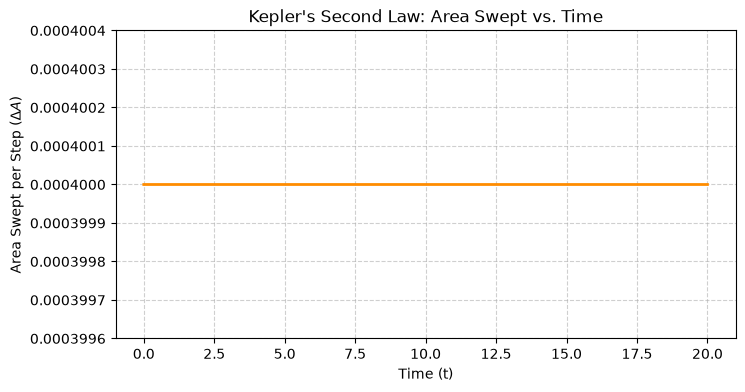

Mean area swept per step: 4.000000e-04


In [13]:
# Compute the 2D cross product magnitude |x*vy - y*vx| for all steps
r_cross_v = np.abs(rs_verlet[:, 0] * vs_verlet[:, 1] - rs_verlet[:, 1] * vs_verlet[:, 0])

# Calculate area swept per step
area_per_step = 0.5 * r_cross_v * dt

# Plot Area Swept vs. Time
plt.figure(figsize=(8, 4))
# FIX: Change 'times' to 'ts_verlet'
plt.plot(ts_verlet, area_per_step, color="darkorange", linewidth=2) 
plt.xlabel("Time (t)")
plt.ylabel(r"Area Swept per Step ($\Delta A$)") # Using raw string to format LaTeX properly
plt.title("Kepler's Second Law: Area Swept vs. Time")
plt.grid(True, linestyle="--", alpha=0.6)

# Tighten y-limits to show stability at a microscopic scale
mean_area = np.mean(area_per_step)
plt.ylim(mean_area - 0.001 * mean_area, mean_area + 0.001 * mean_area)

plt.show()

print(f"Mean area swept per step: {mean_area:.6e}")


**Explanation:** This is equivalent to angular-momentum conservation because the rate at which area is swept out ($dA/dt = \frac{1}{2}|\mathbf{r} \times \mathbf{v}|$) is directly proportional to the constant specific angular momentum ($L/m = |\mathbf{r} \times \mathbf{v}|$) of a central force system.

I simulated 5 different bound orbits with different initial speeds looking for the time that the planet crosses $y = 0$ 

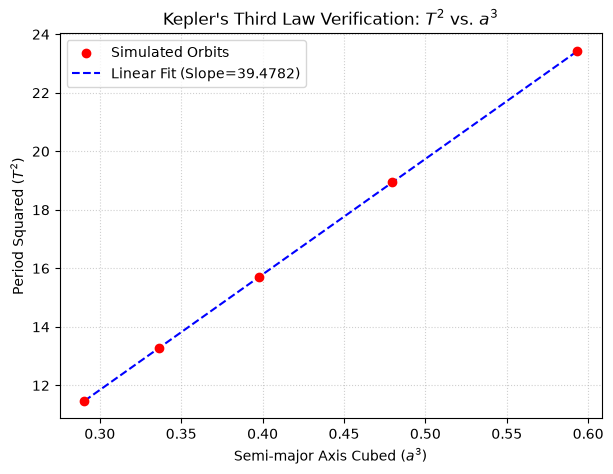

Measured Fit Slope: 39.478167
Theoretical Slope:  39.478418
Percent Difference: 0.0006%


In [14]:
def find_orbit_properties(v0, dt=0.001, max_steps=100000):
    """
    Runs a temporary Velocity Verlet simulation for a given v0.
    Returns: (a, T) semi-major axis and orbital period.
    """
    # Initial conditions
    r = np.array([1.0, 0.0])
    v = np.array([0.0, v0])
    a = accel(r)
    
    positions = [r.copy()]
    times = [0.0]
    period = None
    
    for step in range(1, max_steps):
        r, v, a = verlet_step(r, v, a, dt, accel)
        positions.append(r.copy())
        current_time = step * dt
        times.append(current_time)
        
        # Check for completed orbit: y crosses from negative to positive, and x > 0
        if len(positions) > 2 and positions[-2][1] < 0 and r[1] >= 0 and r[0] > 0:
            # Linear interpolation for exactly when y = 0
            y1, y2 = positions[-2][1], r[1]
            t1, t2 = times[-2], current_time
            period = t1 + (t2 - t1) * (-y1) / (y2 - y1)
            break
            
    positions = np.array(positions)
    dists = np.linalg.norm(positions, axis=1)
    semi_major_axis = (np.min(dists) + np.max(dists)) / 2.0
    
    return semi_major_axis, period

# Select 5 different initial speeds for bound elliptical orbits
v0_choices = [0.70, 0.75, 0.80, 0.85, 0.90]
a_list = []
T_list = []

for v0 in v0_choices:
    a_val, T_val = find_orbit_properties(v0)
    a_list.append(a_val)
    T_list.append(T_val)

a_array = np.array(a_list)
T_array = np.array(T_list)

# Transform for our linear relationship
a_cubed = a_array**3
T_squared = T_array**2

# Linear fit to calculate the observed slope
slope, intercept = np.polyfit(a_cubed, T_squared, 1)

# Theoretical slope calculation: 4 * pi^2 / (G * M) with G=1, M=1
theoretical_slope = 4 * (np.pi**2)

# Plot T^2 vs a^3
plt.figure(figsize=(7, 5))
plt.scatter(a_cubed, T_squared, color="red", zorder=3, label="Simulated Orbits")
plt.plot(a_cubed, slope * a_cubed + intercept, color="blue", linestyle="--", label=f"Linear Fit (Slope={slope:.4f})")
plt.xlabel("Semi-major Axis Cubed ($a^3$)")
plt.ylabel("Period Squared ($T^2$)")
plt.title("Kepler's Third Law Verification: $T^2$ vs. $a^3$")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

print(f"Measured Fit Slope: {slope:.6f}")
print(f"Theoretical Slope:  {theoretical_slope:.6f}")
print(f"Percent Difference: {abs(slope - theoretical_slope)/theoretical_slope * 100:.4f}%")


**Analysis:**  How well do your measured slopes match theory? What's your main source of error, step size, period-measurement resolution, or semi-major-axis estimation?

My measure slope matched the theory almost exactly with only a percent difference of 0.0006%. This is due to the high accuracy of the new varlet integration method. The largest source of error was the step size as it will always lead to estimations between the steps that causes error in data. With a sufficiently small step size though a very small error is possible. 